# SECOM EDA — 상수 제거 · 상관 기반 중복 정리 · 라벨 관련성 · 정보량

**흐름**
0. 라이브러리 / 경로
1. 데이터 로딩 & 기본 확인
2. 상수 컬럼 제거 → `X1`
3. 결측치 분포 확인 (drop은 아직 안 함)
4. 피처 간 상관: 고상관 쌍 목록
5. 상관 기반 군집 → 그룹별 대표 변수 → `X2`
6. 라벨(양품/불량)과의 상관
7. 양품 vs 불량 상관 구조 비교
8. 엔트로피 · 상호정보량(MI) · JS divergence
9. 중간 결과 저장

> ⚠️ 이 노트북은 **전체 데이터로 보는 EDA**야. 여기서 고른 변수를 그대로 CV 모델에 넣으면 누수니까, 모델링 때는 선택 과정을 Pipeline 안에 넣을 것.

## 0. 라이브러리 / 경로

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyprojroot import here

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform, jensenshannon
from scipy.stats import entropy, fisher_exact, norm

pd.set_option("display.max_columns", 50)

DATA_DIR = here("data/raw")
OUT_DIR = here("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(DATA_DIR)   # ...\SECOM\data\raw 가 나오면 정상

c:\Users\Thinkpad\Desktop\python\SECOM\data\raw


## 1. 데이터 로딩 & 기본 확인

In [2]:
# 피처: 공백 구분, 결측은 NaN
X = pd.read_csv(DATA_DIR / "secom.data", sep=r"\s+", header=None)
X.columns = [f"f{i}" for i in range(X.shape[1])]

# 라벨 + 타임스탬프 (예: -1 "19/07/2008 11:55:00")
y = pd.read_csv(DATA_DIR / "secom_labels.data", sep=" ", header=None,
                names=["label", "timestamp"], quotechar='"')
y["timestamp"] = pd.to_datetime(y["timestamp"], format="%d/%m/%Y %H:%M:%S")

# 두 파일은 같은 줄 순서 → 인덱스가 같아야 concat이 정확히 맞음
assert X.index.equals(y.index)
df = pd.concat([y, X], axis=1)

# 분석용 이진 라벨 (Series): 1 = Fail, 0 = Pass
yb = (y["label"] == 1).astype(int)

print("X :", X.shape)
print("y :", y.shape)
print("df:", df.shape)                      # (1567, 592)
print(y["label"].value_counts())            # -1 = Pass, 1 = Fail
print(f"불량률: {yb.mean():.4f}")            # 약 0.0664
print("기간:", y["timestamp"].min(), "~", y["timestamp"].max())

X : (1567, 590)
y : (1567, 2)
df: (1567, 592)
label
-1    1463
 1     104
Name: count, dtype: int64
불량률: 0.0664
기간: 2008-07-19 11:55:00 ~ 2008-10-17 06:07:00


In [3]:
df

,label,timestamp,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20,f21,f22,...,f565,f566,f567,f568,f569,f570,f571,f572,f573,f574,f575,f576,f577,f578,f579,f580,f581,f582,f583,f584,f585,f586,f587,f588,f589
0,-1,2008-07-19 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,-0.0034,0.9455,202.4396,0.0,7.9558,414.8710,10.0433,0.9680,192.3963,12.5190,1.4026,-5419.00,2916.50,...,NaN,NaN,NaN,NaN,NaN,533.8500,2.1113,8.95,0.3157,3.0624,0.1026,1.6765,14.9509,NaN,NaN,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,-1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,-0.0148,0.9627,200.5470,0.0,10.1548,414.7347,9.2599,0.9701,191.2872,12.4608,1.3825,-5441.50,2604.25,...,NaN,NaN,NaN,NaN,NaN,535.0164,2.4335,5.92,0.2653,2.0111,0.0772,1.1065,10.9003,0.0096,0.0201,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,1,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,0.0013,0.9615,202.0179,0.0,9.5157,416.7075,9.3144,0.9674,192.7035,12.5404,1.4123,-5447.75,2701.75,...,0.6219,0.4122,0.2562,0.4119,68.8489,535.0245,2.0293,11.21,0.1882,4.0923,0.0640,2.0952,9.2721,0.0584,0.0484,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,-1,2008-07-19 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,-0.0033,0.9629,201.8482,0.0,9.6052,422.2894,9.6924,0.9687,192.1557,12.4782,1.4011,-5468.25,2648.25,...,0.1630,3.5611,0.0670,2.7290,25.0363,530.5682,2.0253,9.33,0.1738,2.8971,0.0525,1.7585,8.5831,0.0202,0.0149,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,-1,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,-0.0072,0.9569,201.9424,0.0,10.5661,420.5925,10.3387,0.9735,191.6037,12.4735,1.3888,-5476.25,2635.25,...,NaN,NaN,NaN,NaN,NaN,532.0155,2.0275,8.83,0.2224,3.1776,0.0706,1.6597,10.9698,NaN,NaN,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1562,-1,2008-10-16 15:13:00,2899.41,2464.36,2179.7333,3085.3781,1.4843,100.0,82.2467,0.1248,1.3424,-0.0045,-0.0057,0.9579,203.9867,0.0,11.7692,419.3404,10.2397,0.9693,193.7470,12.5373,1.4072,-5418.75,2608.00,...,0.0877,2.0902,0.0382,1.8844,15.4662,536.3418,2.0153,7.98,0.2363,2.6401,0.0785,1.4879,11.7256,0.0068,0.0138,0.0047,203.1720,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.1720
1563,-1,2008-10-16 20:49:00,3052.31,2522.55,2198.5667,1124.6595,0.8763,100.0,98.4689,0.1205,1.4333,-0.0061,-0.0093,0.9618,204.0173,0.0,9.1620,405.8178,10.2285,0.9696,193.7889,12.4020,1.3949,-6408.75,2277.50,...,0.1308,1.7420,0.0495,1.7089,20.9118,537.9264,2.1814,5.48,0.3891,1.9077,0.1213,1.0187,17.8379,NaN,NaN,NaN,NaN,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.1720
1564,-1,2008-10-17 05:26:00,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.4555,1.4256,-5153.25,2707.00,...,0.2388,4.4128,0.0965,4.3197,29.0954,530.3709,2.3435,6.49,0.4154,2.1760,0.1352,1.2237,17.7267,0.0197,0.0086,0.0025,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231
1565,-1,2008-10-17 06:01:00,2894.92,2532.01,2177.0333,1183.7287,1.5726,100.0,98.7978,0.1213,1.4622,-0.0072,0.0032,0.9694,197.2448,0.0,9.7354,401.9153,9.8630,0.9740,187.3818,12.3937,1.3868,-5271.75,2676.50,...,0.0877,2.0902,0.0382,1.8844,15.4662,534.3936,1.9098,9.13,0.3669,3.2524,0.1040,1.7085,19.2104,0.0262,0.0245,0.0075,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941


In [4]:
yb

0       0
1       0
2       1
3       0
4       0
       ..
1562    0
1563    0
1564    0
1565    0
1566    0
Name: label, Length: 1567, dtype: int64

## 2. 상수 컬럼 제거 → `X1`
- `nunique()`는 NaN을 빼고 셈 → 전부 NaN인 컬럼은 0이 나오므로 `<= 1`로 같이 제거
- 원본 `X`는 덮어쓰지 않고 남겨둠

In [5]:
nu = X.nunique(dropna=True)
const_cols = nu[nu <= 1].index

# 값은 상수인데 NaN이 섞인 컬럼 → "측정 여부" 정보가 남아 있을 수 있어 확인
const_with_na = [c for c in const_cols if X[c].isna().any()]
print(len(const_cols), "개 상수 컬럼 /", len(const_with_na), "개는 결측 포함")

def na_fail_check(cols):
    """결측일 때 vs 관측일 때 불량률 비교 + Fisher 정확검정 p값"""
    rows = []
    for c in cols:
        is_na = X[c].isna()
        if is_na.all() or not is_na.any():   # 전부 결측이거나 결측이 없으면 비교 불가
            continue
        table = pd.crosstab(is_na, yb).reindex(index=[False, True], columns=[0, 1], fill_value=0)
        rows.append(dict(
            feature=c,
            na_ratio=is_na.mean(),
            fail_if_na=yb[is_na].mean(),
            fail_if_obs=yb[~is_na].mean(),
            p_value=fisher_exact(table.values)[1],
        ))
    if not rows:
        return pd.DataFrame()
    out = pd.DataFrame(rows).set_index("feature")
    out["diff"] = out["fail_if_na"] - out["fail_if_obs"]
    return out.sort_values("p_value")

na_fail_check(const_with_na)

116 개 상수 컬럼 / 116 개는 결측 포함


,na_ratio,fail_if_na,fail_if_obs,p_value,diff
feature,,,,,
f192,0.002553,0.25,0.065899,0.240404,0.184101
f190,0.002553,0.25,0.065899,0.240404,0.184101
f191,0.002553,0.25,0.065899,0.240404,0.184101
f193,0.002553,0.25,0.065899,0.240404,0.184101
f194,0.002553,0.25,0.065899,0.240404,0.184101
...,...,...,...,...,...
f534,0.005743,0.00,0.066752,1.000000,-0.066752
f535,0.005743,0.00,0.066752,1.000000,-0.066752
f536,0.005743,0.00,0.066752,1.000000,-0.066752


In [6]:
x_g = na_fail_check(const_with_na)

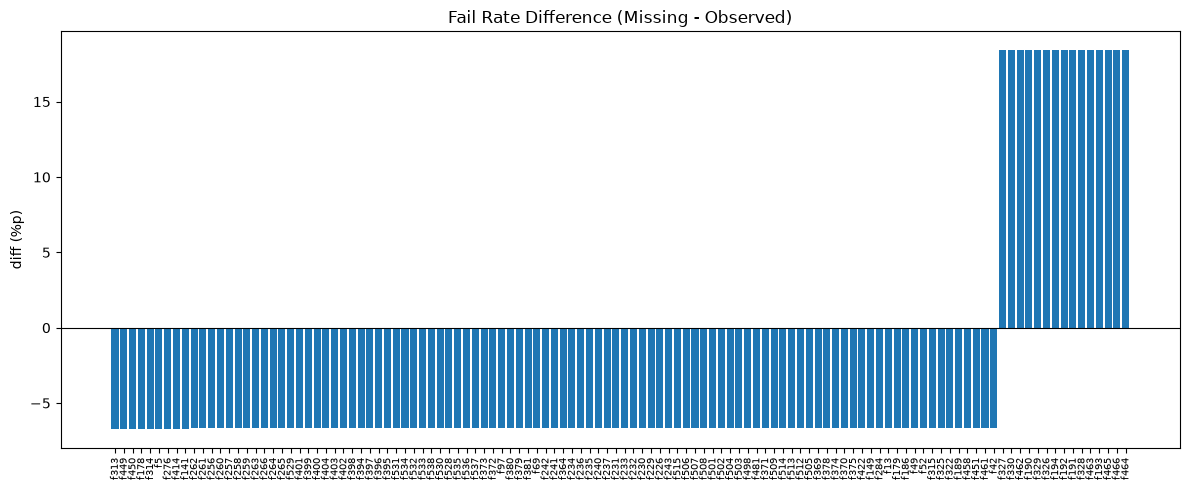

In [7]:
d = x_g["diff"].sort_values() * 100   # %p 단위

plt.figure(figsize=(12, 5))
plt.bar(d.index, d.values)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("diff (%p)")
plt.title("Fail Rate Difference (Missing - Observed)")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

In [8]:
x_g["n_na"] = (x_g["na_ratio"] * len(X)).round().astype(int)
print(x_g.groupby(["n_na", "diff"])[["p_value"]].agg(["count", "first"]))

               p_value          
                 count     first
n_na diff                       
1    -0.066411      12  1.000000
3    -0.066496       4  1.000000
4     0.184101      15  0.240404
6    -0.066624      43  1.000000
9    -0.066752      33  1.000000
14   -0.066967       4  0.617665
24   -0.067401       5  0.400011


상수 컬럼 116개는 모두 결측을 포함하지만, 결측 샘플이 1~24개에 불과하고 7개 결측 패턴 모두 Fisher 검정에서 비유의(최소 p = 0.24) → 결측 지시변수 없이 전부 제거. X: 590 → 474

In [9]:
X1 = X.drop(columns=const_cols)
print(X.shape, "→", X1.shape)   # (1567, 474) 예상

(1567, 590) → (1567, 474)


### 상수 컬럼 결측 분석 결과

값이 하나뿐인 상수 컬럼 **116개**를 찾았다. 전부 결측을 포함하고 있어서, 결측 여부 자체가 불량과 관련 있는지 **Fisher 정확검정**으로 확인했다.

116개 컬럼은 결측 샘플 수 기준으로 **7개 결측 패턴**으로 묶인다.

| 결측 샘플 수 | 컬럼 수 | 결측 중 불량 | diff (%p) | p-value |
|---|---|---|---|---|
| 1 | 12 | 0 | -6.64 | 1.000 |
| 3 | 4 | 0 | -6.65 | 1.000 |
| 4 | 15 | 1 (25%) | +18.41 | 0.240 |
| 6 | 43 | 0 | -6.66 | 1.000 |
| 9 | 33 | 0 | -6.68 | 1.000 |
| 14 | 4 | 0 | -6.70 | 0.618 |
| 24 | 5 | 0 | -6.74 | 0.400 |

- diff = 결측 시 불량률 - 관측 시 불량률 (전체 불량률 약 6.6%)
- 다중비교 보정 기준: Bonferroni 0.05 / 116 ≈ 0.0004
- +18.4%p로 커 보이는 패턴도 결측 4개 중 불량 1개로, 우연으로 설명 가능한 수준

**결론**: 7개 패턴 모두 유의하지 않아(최소 p = 0.24) 결측 지시변수 없이 116개 전부 제거했다. 단, 결측 샘플이 1~24개로 적어 "영향 없음"을 증명한 것은 아니고 "영향이 있다는 근거를 찾지 못한 것"이다.

**X: 590 → 474**

## 3. 결측치 분포 확인
기준(50%? 70%?)은 여기 결과를 보고 정함. **아직 drop 안 함.**

count    474.000000
mean       0.055383
std        0.170734
min        0.000000
25%        0.000638
50%        0.002553
75%        0.006382
max        0.911934
dtype: float64
결측 > 10%: 52개
결측 > 30%: 32개
결측 > 50%: 28개
결측 > 70%: 8개
결측 > 90%: 4개


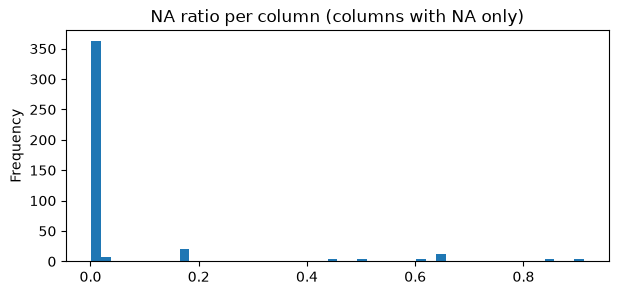

In [10]:
na_ratio = X1.isna().mean().sort_values(ascending=False)
print(na_ratio.describe())
for th in [0.1, 0.3, 0.5, 0.7, 0.9]:
    print(f"결측 > {th:.0%}: {(na_ratio > th).sum()}개")

na_ratio[na_ratio > 0].plot.hist(bins=50, figsize=(7, 3), title="NA ratio per column (columns with NA only)")
plt.show()

In [11]:
# 결측 50% 초과 컬럼: 결측 여부 자체가 불량과 관련 있는지
# p_value가 작고 diff가 크면 → 값은 버려도 "결측 지시변수"로 남길 후보
high_na = na_ratio[na_ratio > 0.5].index
na_fail_check(high_na)

,na_ratio,fail_if_na,fail_if_obs,p_value,diff
feature,,,,,
f346,0.506701,0.045340,0.087969,0.000761,-0.042629
f73,0.506701,0.045340,0.087969,0.000761,-0.042629
f345,0.506701,0.045340,0.087969,0.000761,-0.042629
f72,0.506701,0.045340,0.087969,0.000761,-0.042629
f245,0.649649,0.072692,0.054645,0.201655,0.018047
f246,0.649649,0.072692,0.054645,0.201655,0.018047
f111,0.649649,0.072692,0.054645,0.201655,0.018047
f383,0.649649,0.072692,0.054645,0.201655,0.018047
f518,0.649649,0.072692,0.054645,0.201655,0.018047


## 4. 피처 간 상관: 고상관 쌍 목록
**쌍 단위로 눈으로 확인**하는 단계 (그룹 묶기는 5번에서)

In [12]:
# ── 상관계수 행렬 ─────────────────────────────────────
# NaN이 있는 행은 쌍마다 알아서 제외하고 계산 (pairwise)
corr = X1.corr()

# ── 고상관 쌍 목록 ────────────────────────────────────
# 상관행렬은 대칭 → 위쪽 삼각형만 남김 (k=1: 대각선도 제외)
mask_upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)
# stack(): 행렬을 (변수1, 변수2) → r 목록으로 펼침, 가려진 NaN은 자동 제외
pairs = corr.where(mask_upper).stack()
# |r| > 0.95인 쌍만, 절댓값 큰 순
high = pairs[pairs.abs() > 0.95].sort_values(key=abs, ascending=False)

print(len(high), "쌍이 |r| > 0.95")
# == 1.0 대신 isclose: 0.9999999999999997 같은 부동소수점 오차 + r = -1 도 포함
print(np.isclose(high.abs(), 1.0).sum(), "쌍이 |r| ≈ 1 (완전 중복)")

329 쌍이 |r| > 0.95
31 쌍이 |r| ≈ 1 (완전 중복)


In [13]:
# 상위 쌍마다 "둘 다 관측된 샘플 수" 확인
# n_overlap이 작으면 우연히 r ≈ 1이 나왔을 수도 있음
top = high.head(30).rename_axis(["a", "b"]).reset_index(name="r")
top["n_overlap"] = [(X1[a].notna() & X1[b].notna()).sum() for a, b in zip(top["a"], top["b"])]
top

,a,b,r,n_overlap
0,f492,f545,1.000000,226
1,f358,f544,1.000000,226
2,f209,f342,1.000000,1561
3,f209,f347,1.000000,1561
4,f342,f347,1.000000,1561
5,f579,f587,1.000000,618
6,f74,f342,1.000000,1561
7,f74,f478,1.000000,1561
8,f74,f209,1.000000,1561
9,f580,f588,1.000000,618


## 5. 상관 기반 군집 → 그룹별 대표 변수 → `X2`
- 거리 = 1 − |r|
- average linkage: 두 그룹 사이 **모든 쌍 거리의 평균**으로 합칠지 판단
- t = 0.05 → 평균 |r| ≥ 0.95인 변수끼리 한 그룹

In [14]:
def corr_groups(corr_mat, t=0.05):
    """상관행렬 → 계층적 군집 → 변수별 그룹 번호"""
    # |r| = 1 → 거리 0 (중복), |r| = 0 → 거리 1 (무관)
    # abs: r = -0.99처럼 반대로 움직여도 담긴 정보는 같음
    # fillna(0): 상관계수를 못 구한 쌍은 "무관" 취급
    dist = (1 - corr_mat.abs().fillna(0)).to_numpy(copy=True)   # copy: pandas 3에서 읽기전용 방지
    np.fill_diagonal(dist, 0)                     # 자기 자신 거리 = 0 (계산 오차 방지)
    dist = (dist + dist.T) / 2                    # 대칭 보장
    Z = linkage(squareform(dist, checks=False), method="average")
    return pd.Series(fcluster(Z, t=t, criterion="distance"),
                     index=corr_mat.columns, name="group")

groups = corr_groups(corr, t=0.05)
sizes = groups.value_counts()
print("전체 그룹 수:", len(sizes), "/ 크기 2 이상 그룹:", (sizes > 1).sum())
sizes.head(10)

전체 그룹 수: 282 / 크기 2 이상 그룹: 113


group
50     9
21     7
242    6
112    6
226    4
196    4
161    4
193    4
74     4
93     3
Name: count, dtype: int64

In [15]:
# t 값에 따라 남는 변수 수가 어떻게 변하는지 (기준 정하는 참고용)
for t in [0.02, 0.05, 0.1, 0.2]:
    print(f"t={t:<5} (평균 |r| ≥ {1-t:.2f}) → 그룹 {corr_groups(corr, t).nunique()}개")

t=0.02  (평균 |r| ≥ 0.98) → 그룹 335개
t=0.05  (평균 |r| ≥ 0.95) → 그룹 282개
t=0.1   (평균 |r| ≥ 0.90) → 그룹 256개
t=0.2   (평균 |r| ≥ 0.80) → 그룹 231개


In [16]:
# ── 그룹마다 대표 변수 1개 ────────────────────────────
# 기준: 결측 비율 최소 (라벨을 안 보는 기준 → 모델링에 써도 누수 없음)
# 결측이 같으면 원래 컬럼 순서가 앞선 변수 (stable 정렬)
rep = (pd.DataFrame({"group": groups, "na": X1.isna().mean()})
         .sort_values("na", kind="stable")
         .groupby("group").head(1)
         .index)
rep = [c for c in X1.columns if c in set(rep)]   # 원래 컬럼 순서 유지

X2 = X1[rep]
print(X1.shape, "→", X2.shape)

(1567, 474) → (1567, 282)


In [17]:
# 확인용: 크기 2 이상인 그룹에 어떤 변수가 묶였고 누가 대표인지
multi = sizes[sizes > 1].index
grp_table = (pd.DataFrame({"group": groups, "na_ratio": X1.isna().mean()})
               .loc[lambda d: d["group"].isin(multi)]
               .assign(is_rep=lambda d: d.index.isin(rep),
                       size=lambda d: d["group"].map(sizes))
               .sort_values(["size", "group", "na_ratio"], ascending=[False, True, True]))
grp_table.head(40)

,group,na_ratio,is_rep,size
f244,50,0.649649,True,9
f245,50,0.649649,False,9
f246,50,0.649649,False,9
f382,50,0.649649,False,9
f383,50,0.649649,False,9
f384,50,0.649649,False,9
f516,50,0.649649,False,9
f517,50,0.649649,False,9
f518,50,0.649649,False,9
f148,21,0.001276,True,7


In [18]:
# (선택) Spearman으로 같은 작업 → Pearson과 비교
# Spearman은 순위 기반이라 이상치에 강하고, 단조 비선형 관계도 잡음
corr_sp = X1.corr(method="spearman")
groups_sp = corr_groups(corr_sp, t=0.05)
print("Pearson 그룹 수:", groups.nunique(), "/ Spearman 그룹 수:", groups_sp.nunique())

Pearson 그룹 수: 282 / Spearman 그룹 수: 302


## 6. 라벨(양품/불량)과의 상관
각 피처 하나하나가 불량과 얼마나 관련 있는지. 이상치가 많아 Spearman도 같이 봄.

In [19]:
lab = pd.DataFrame({
    "pearson":  X2.corrwith(yb),
    "spearman": X2.corrwith(yb, method="spearman"),
    "na_ratio": X2.isna().mean(),
})
lab = lab.reindex(lab["spearman"].abs().sort_values(ascending=False).index)
lab.head(20)

,pearson,spearman,na_ratio
f247,0.080991,0.167224,0.456286
f59,0.155796,0.165942,0.004467
f158,0.121258,0.151011,0.911934
f103,0.151203,0.145108,0.001276
f111,-0.113950,-0.136634,0.649649
f385,0.042056,0.127859,0.456286
f510,0.131593,0.117378,0.001276
f205,0.053652,0.103029,0.003829
f129,0.103373,0.102987,0.005743
f28,-0.107252,-0.100586,0.001276


<Axes: title={'center': 'Pearson correlation with label'}>

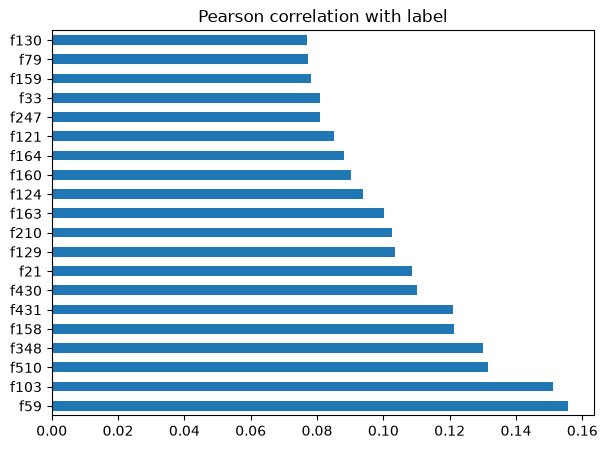

In [20]:
lab['pearson'].sort_values(ascending=False).head(20).plot.barh(figsize=(7, 5), title="Pearson correlation with label")

<Axes: title={'center': 'Pearson correlation with label'}>

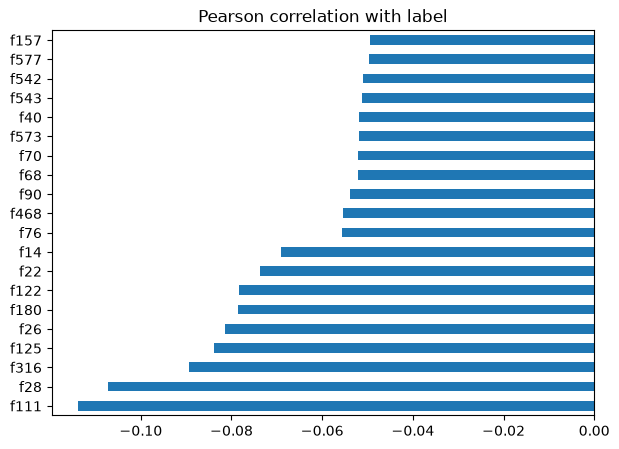

In [21]:
lab['pearson'].sort_values().head(20).plot.barh(figsize=(7, 5), title="Pearson correlation with label")

<Axes: title={'center': 'Spearman correlation with label (descending)'}>

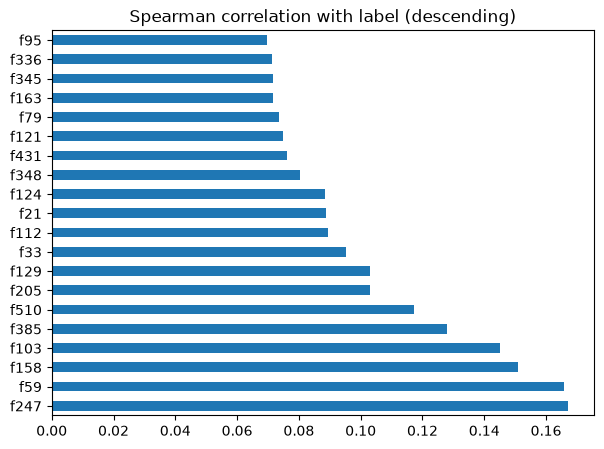

In [22]:
lab['spearman'].sort_values(ascending=False).head(20).plot.barh(figsize=(7, 5), title="Spearman correlation with label (descending)")

<Axes: title={'center': 'Spearman correlation with label (ascending)'}>

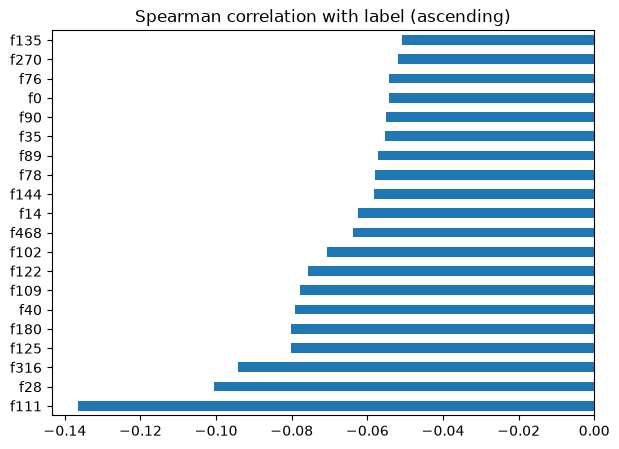

In [23]:
lab['spearman'].sort_values().head(20).plot.barh(figsize=(7, 5), title="Spearman correlation with label (ascending)")

## 7. 양품 vs 불량 상관 구조 비교
불량일 때만 변수 간 관계가 깨지는 쌍 찾기.
불량이 104개뿐이라 노이즈가 커서 **Fisher z 검정 + Bonferroni 보정**으로 거름.

In [24]:
def pairwise_n(D):
    """변수 쌍마다 둘 다 관측된 샘플 수 행렬"""
    M = D.notna().astype(int).to_numpy(copy=True)
    return pd.DataFrame(M.T @ M, index=D.columns, columns=D.columns)

Xp, Xf = X2[yb == 0], X2[yb == 1]
c_pass = Xp.corr(min_periods=30)   # 겹치는 샘플 30개 미만인 쌍은 NaN
c_fail = Xf.corr(min_periods=30)
n_pass, n_fail = pairwise_n(Xp), pairwise_n(Xf)

mask = np.triu(np.ones(c_pass.shape, dtype=bool), k=1)
cmp_ = pd.DataFrame({
    "r_pass": c_pass.where(mask).stack(),
    "r_fail": c_fail.where(mask).stack(),
    "n_pass": n_pass.where(mask).stack(),
    "n_fail": n_fail.where(mask).stack(),
}).dropna()

# Fisher z 변환: 상관계수 차이를 정규분포로 검정
z1 = np.arctanh(cmp_["r_pass"].clip(-0.9999, 0.9999))
z2 = np.arctanh(cmp_["r_fail"].clip(-0.9999, 0.9999))
se = np.sqrt(1 / (cmp_["n_pass"] - 3) + 1 / (cmp_["n_fail"] - 3))
cmp_["diff"] = cmp_["r_fail"] - cmp_["r_pass"]
cmp_["z"] = (z2 - z1) / se
cmp_["p_value"] = 2 * norm.sf(cmp_["z"].abs())
cmp_["p_bonf"] = (cmp_["p_value"] * len(cmp_)).clip(upper=1)   # 쌍이 많으니 다중비교 보정

print(len(cmp_), "쌍 검정 /", (cmp_["p_bonf"] < 0.05).sum(), "쌍이 보정 후 유의")
cmp_.sort_values("p_value").head(20)

38701 쌍 검정 / 274 쌍이 보정 후 유의


r_pass    r_fail  n_pass  n_fail      diff          z  \
f67  f204  0.876767  1.000000  1457.0   104.0  0.123233  34.888704   
f114 f521  0.522229  0.992148  1463.0   104.0  0.469920  21.272786   
f33  f35   0.260063  0.982377  1462.0   104.0  0.722315  20.363999   
     f34   0.420017  0.978276  1462.0   104.0  0.558259  17.572792   
f4   f413  0.944710 -0.010853  1449.0   104.0 -0.955563 -17.401775   
f67  f337  0.171692  0.957363  1456.0   104.0  0.785672  16.908100   
f4   f7   -0.921318  0.051652  1446.0   104.0  0.972971  16.024702   
f34  f35   0.760539  0.987558  1462.0   104.0  0.227019  14.960771   
f204 f337  0.428230  0.957355  1456.0   104.0  0.529126  14.144228   
f167 f438  0.637605  0.973152  1462.0   103.0  0.335548  13.490128   
f12  f18   0.679494  0.976279  1460.0   104.0  0.296785  13.442131   
f67  f200  0.439874  0.951411  1456.0   104.0  0.511537  13.355979   
f203 f336  0.678568  0.972545  1456.0   104.0  0.293977  12.738241   
f67  f202  0.378920  0.936306  1456.0   104.0  0.557385  12.714982   
f207 f337  0.429187  0.936033  1456.0   104.0  0.506845  12.109479   
f205 f337  0.313974  0.916256  1456.0   104.0  0.602282  12.052320   
f147 f148  0.894577  0.214434  1461.0   104.0 -0.680142 -11.920878   
f200 f337  0.498456  0.942902  1456.0   104.0  0.444446  11.820117   
f32  f35   0.495630  0.941811  1462.0   104.0  0.446181  11.763452   
f202 f337  0.849319  0.984804  1456.0   104.0  0.135485  11.490518   

                 p_value         p_bonf  
f67  f204  1.102975e-266  4.268625e-262  
f114 f521  2.028682e-100   7.851202e-96  
f33  f35    3.489072e-92   1.350306e-87  
     f34    3.980927e-69   1.540659e-64  
f4   f413   7.998520e-68   3.095507e-63  
f67  f337   3.921463e-64   1.517645e-59  
f4   f7     8.590207e-58   3.324496e-53  
f34  f35    1.324817e-50   5.127175e-46  
f204 f337   2.027301e-45   7.845856e-41  
f167 f438   1.787888e-41   6.919305e-37  
f12  f18    3.424306e-41   1.325241e-36  
f67  f200   1.093115e-40   4.230463e-36  
f203 f336   3.624759e-37   1.402818e-32  
f67  f202   4.882195e-37   1.889458e-32  
f207 f337   9.408992e-34   3.641374e-29  
f205 f337   1.885676e-33   7.297754e-29  
f147 f148   9.213271e-33   3.565628e-28  
f200 f337   3.072553e-32   1.189109e-27  
f32  f35    6.022100e-32   2.330613e-27  
f202 f337   1.472258e-30   5.697784e-26

## 8. 엔트로피 · 상호정보량(MI) · JS divergence
- 전체 데이터 기준 **같은 bin 경계**(10분위)로 구간화 → 두 클래스 분포 비교 가능
- 결측은 별도 bin(-1) → 결측 여부 자체의 정보도 반영
- `H_pass`, `H_fail`: 클래스별 엔트로피 (H_fail이 확 낮으면 불량이 특정 구간에 몰림)
- `MI`, `JS`: 두 분포가 얼마나 다른지 = 불량 설명력 → **순위 매길 때 쓰는 지표**

In [25]:
def info_table(D, target, n_bins=10):
    rows = []
    for c in D.columns:
        # 분위수 구간화 (중복 경계는 합침), 결측 → -1
        b = pd.qcut(D[c], n_bins, labels=False, duplicates="drop").fillna(-1)
        ct = pd.crosstab(b, target).reindex(columns=[0, 1], fill_value=0)  # 행: bin, 열: 0/1
        p_pass = ct[0] / ct[0].sum()
        p_fail = ct[1] / ct[1].sum()
        p_all = ct.sum(axis=1) / ct.values.sum()
        w = ct.sum(axis=0) / ct.values.sum()          # 클래스 비율
        H_pass = entropy(p_pass, base=2)
        H_fail = entropy(p_fail, base=2)
        # MI = H(X) - H(X|Y)
        mi = entropy(p_all, base=2) - (w[0] * H_pass + w[1] * H_fail)
        rows.append(dict(feature=c, n_bins=len(ct), H_pass=H_pass, H_fail=H_fail,
                         MI=mi, JS=jensenshannon(p_pass, p_fail, base=2)))
    return pd.DataFrame(rows).set_index("feature")

info = info_table(X2, yb).sort_values("MI", ascending=False)
info.head(20)

,n_bins,H_pass,H_fail,MI,JS
feature,,,,,
f59,11,3.347467,2.933979,0.028361,0.332028
f247,11,2.768292,2.879011,0.024825,0.321940
f103,11,3.329825,3.012064,0.021870,0.298018
f64,11,3.348222,3.063771,0.019048,0.270703
f348,11,3.386660,3.075944,0.019026,0.273024
f205,11,3.345135,3.104839,0.016222,0.246996
f65,11,3.348527,3.103324,0.016139,0.251765
f130,11,3.353893,3.100371,0.015921,0.268815
f153,11,3.332537,3.115278,0.015069,0.259113


In [26]:
# ── MI 과대추정 체크: 라벨을 섞은 기준선 ──────────────────
# 라벨을 무작위로 섞으면 진짜 관계는 사라짐 → 이때 나오는 MI는 "우연 수준"
# 여러 번 섞어서 변수별 최대치를 모으고, 그 상위 95% 값을 문턱으로 사용
rng = np.random.default_rng(0)
null_max = []
for i in range(5):   # 시간 여유 있으면 20 이상 권장
    yb_shuf = pd.Series(rng.permutation(yb.values), index=yb.index)
    null_max.append(info_table(X2, yb_shuf)["MI"].max())
mi_threshold = np.quantile(null_max, 0.95)
print(f"우연 수준 MI 문턱: {mi_threshold:.4f}")

info["MI_significant"] = info["MI"] > mi_threshold
print(info["MI_significant"].sum(), "개 변수가 문턱 초과")
info[info["MI_significant"]].head(20)

우연 수준 MI 문턱: 0.0139
14 개 변수가 문턱 초과


,n_bins,H_pass,H_fail,MI,JS,MI_significant
feature,,,,,,
f59,11,3.347467,2.933979,0.028361,0.332028,True
f247,11,2.768292,2.879011,0.024825,0.321940,True
f103,11,3.329825,3.012064,0.021870,0.298018,True
f64,11,3.348222,3.063771,0.019048,0.270703,True
f348,11,3.386660,3.075944,0.019026,0.273024,True
f205,11,3.345135,3.104839,0.016222,0.246996,True
f65,11,3.348527,3.103324,0.016139,0.251765,True
f130,11,3.353893,3.100371,0.015921,0.268815,True
f153,11,3.332537,3.115278,0.015069,0.259113,True


In [27]:
# 상관(6번)과 MI(8번) 상위 변수 비교 → 둘 다 뽑힌 변수가 강한 후보
k = 20
top_corr = set(lab.head(k).index)
top_mi = set(info.head(k).index)
print("둘 다 상위:", sorted(top_corr & top_mi))
print("상관만:", sorted(top_corr - top_mi))
print("MI만:", sorted(top_mi - top_corr))   # 비선형/결측 패턴 신호일 가능성

둘 다 상위: ['f103', 'f111', 'f125', 'f129', 'f205', 'f21', 'f247', 'f28', 'f33', 'f348', 'f385', 'f510', 'f59']
상관만: ['f109', 'f112', 'f124', 'f158', 'f180', 'f316', 'f40']
MI만: ['f130', 'f153', 'f19', 'f571', 'f64', 'f65', 'f91']


## 9. 중간 결과 저장

In [28]:
# summary = (lab.join(info, how="outer")
#                .join(groups.rename("corr_group"))
#                .sort_values("MI", ascending=False))
# summary.to_csv(OUT_DIR / "feature_summary.csv")
df.to_parquet(OUT_DIR / "secom.parquet")          # 다음부터 pd.read_parquet로 빠르게 로딩
pd.Series(rep, name="feature").to_csv(OUT_DIR / "rep_features.csv", index=False)
print("저장 완료:", OUT_DIR)

저장 완료: c:\Users\Thinkpad\Desktop\python\SECOM\data\processed
